## Comparison of Training Curves for the Simulation Scenarios (T1-T6)

Directory structure (this notebook sits at the same level as the `Learning Curves` folder):

```
Learning Curves/
└── eps10_steps10000/
    ├── T1/  ...  T6/          # 6 simulation scenarios
    │   ├── DDPG_P1/         # DDPG (in-task training) x parameter set P1
    │   ├── DDPG_P2/         # DDPG x parameter set P2
    │   ├── Meta_P3/         # MetaSet (meta-initialization) x parameter set P3
    │   ├── Scratch_P1/      # MetaSet (random initialization) x parameter set P1
    │   └── Scratch_P2/      # Scratch x parameter set P2
```

Unified convention: each folder contains one `.npy` data file with shape [10 episodes, 10000 steps].
For each algorithm x parameter set, only **1 curve** is plotted: first apply a moving average to each episode, then take the mean over the 10 episodes
(the shaded band is +/-1 std across episodes; delete the fill_between line if not needed); missing directories print a warning and are skipped automatically.

In [19]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# ===== Path configuration: this notebook sits at the same level as the "Learning Curves" folder =====
BASE = Path.cwd()
ROOT = BASE / 'Learning Curves' / 'eps10_steps10000'
assert ROOT.exists(), f'Data directory not found: {ROOT}'

# ===== Scenario and algorithm x parameter set configuration =====
SCENARIOS = [f'T{i}' for i in range(1, 7)]   # T1~T6 (missing scenarios are skipped automatically)
# ALGO_PARAMS = {                              # parameter-set folders for each algorithm
#     'DDPG':    ['P1', 'P2', 'P3','P4'],
#     'Meta':    ['P3','P4'],
#     'Scratch': ['P1', 'P2', 'P3','P4'],
# }
ALGO_PARAMS = {                              # parameter-set folders for each algorithm
    'DDPG':    ['P1', 'P2', 'P3'],
    'Meta':    ['P3'],
    'Scratch': ['P1', 'P2', 'P3'],
}
# Scenario configuration (M x L x K), used for subplot titles
SCENARIO_CONFIG = {
    'T1': (4, 4, 4),
    'T2': (6, 12, 6),
    'T3': (6, 12, 3),
    'T4': (16, 16, 8),
    'T5': (8, 32, 8),
    'T6': (8, 16, 16),
}
SCENARIO_INFO = {t: f'{c[0]}×{c[1]}×{c[2]} (M×L×K)' for t, c in SCENARIO_CONFIG.items()}

HIDDEN = 256

def ddpg_param_count(M, L, K, h=HIDDEN):
    action_dim = 2 * M * K + 2 * L
    state_dim = action_dim + 2 * K + 2 * K * L * M
    n = (state_dim * h + h) + (h * h + h)             # Actor_Feature: l1 + l2
    n += h * action_dim + action_dim                  # Actor.l3
    n += (state_dim * h + h) + ((h + action_dim) * h + h) + (h + 1)   # Critic: l1 + l2 + l3
    return n

PARAM_COUNT = {t: ddpg_param_count(*c) for t, c in SCENARIO_CONFIG.items()}
for t, n in PARAM_COUNT.items():
    print(f'  {t}: {n:,} params ({n/1e6:.2f}M)' if n >= 1e6 else f'  {t}: {n:,} params ({n/1e3:.1f}K)')

def fmt_params(n):
    """Format parameter counts: 12345 -> '12.3K', 1_234_567 -> '1.23M'"""
    if n is None:
        return None
    return f'{n/1e6:.2f}M' if n >= 1e6 else f'{n/1e3:.1f}K'

def annotate_params(ax, tid):
    """Annotate the parameter count in the bottom-right corner of the subplot (white semi-transparent box; does not obscure curves)"""
    s = fmt_params(PARAM_COUNT.get(tid))
    if s:
        ax.text(0.97, 0.04, f'DDPG #Params: {s}', transform=ax.transAxes,
                ha='right', va='bottom', fontsize=plt.rcParams['font.size'], color='#444444',
                bbox=dict(boxstyle='round,pad=0.25', fc='white', ec='#bbbbbb', alpha=0.85))

def load_dir(d, n_eps=10, n_steps=10000):
    """Load the .npy data file in the folder; each file contains n_eps episodes x n_steps steps.
    Returns [ep0, ..., ep9], each a [n_steps] 1-D array."""
    files = sorted(d.glob('*.npy'))
    if not files:
        return []
    epis = []
    for f in files:
        arr = np.load(f)
        if arr.ndim == 1:                      # flattened storage: [n_eps*n_steps]
            arr = arr.reshape(n_eps, n_steps)
        epis.extend(arr.reshape(arr.shape[0], -1))   # [n_eps, n_steps] -> list of episodes
    return epis

# SCENE_DATA[tid][algo][param] = [episodes...]
SCENE_DATA = {}
for tid in SCENARIOS:
    tdir = ROOT / tid
    if not tdir.is_dir():
        print(f'[SKIP] {tid}: directory does not exist -> {tdir}')
        continue
    print(f'--- {tid} ---')
    SCENE_DATA[tid] = {}
    for algo, params in ALGO_PARAMS.items():
        SCENE_DATA[tid][algo] = {}
        for p in params:
            d = tdir / f'{algo}_{p}'
            epis = load_dir(d)
            if not epis:
                print(f'  [WARNING] {algo}_{p}: no .npy file found -> {d}')
                continue
            SCENE_DATA[tid][algo][p] = epis
            print(f'  {algo}_{p}: {len(epis)} episodes, T={epis[0].shape[0]}')
    if not any(SCENE_DATA[tid][a] for a in SCENE_DATA[tid]):
        del SCENE_DATA[tid]
print(f'\nSuccessfully loaded {len(SCENE_DATA)}/{len(SCENARIOS)} scenarios')

  T1: 242,985 params (243.0K)
  T2: 679,265 params (679.3K)
  T3: 418,109 params (418.1K)
  T4: 2,532,897 params (2.53M)
  T5: 2,434,497 params (2.43M)
  T6: 2,541,089 params (2.54M)
--- T1 ---
  DDPG_P1: 10 episodes, T=10000
  DDPG_P2: 10 episodes, T=10000
  DDPG_P3: 10 episodes, T=10000
  Meta_P3: 10 episodes, T=10000
  Scratch_P1: 10 episodes, T=10000
  Scratch_P2: 10 episodes, T=10000
  Scratch_P3: 10 episodes, T=10000
--- T2 ---
  DDPG_P1: 10 episodes, T=10000
  DDPG_P2: 10 episodes, T=10000
  DDPG_P3: 10 episodes, T=10000
  Meta_P3: 10 episodes, T=10000
  Scratch_P1: 10 episodes, T=10000
  Scratch_P2: 10 episodes, T=10000
  Scratch_P3: 10 episodes, T=10000
--- T3 ---
  DDPG_P1: 10 episodes, T=10000
  DDPG_P2: 10 episodes, T=10000
  DDPG_P3: 10 episodes, T=10000
  Meta_P3: 10 episodes, T=10000
  Scratch_P1: 10 episodes, T=10000
  Scratch_P2: 10 episodes, T=10000
  Scratch_P3: 10 episodes, T=10000
--- T4 ---
  DDPG_P1: 10 episodes, T=10000
  DDPG_P2: 10 episodes, T=10000
  DDPG_P3:

In [22]:
# ===== Moving average =====
W = 100
def curve(R, W=W):
    R = np.asarray(R).reshape(-1)
    return np.convolve(R, np.ones(W) / W, mode='valid')

# ===== Styles: colors use three color families by algorithm; P1/P2 are distinguished by shades within the same family; overlay line widths/styles (P2 additionally uses hollow circle markers) =====
import matplotlib.colors as mcolors
ALGO_COLOR = {
    'DDPG':    'b',
    'Meta':    "#D55E00",  
    'Scratch': 'g', 
}
ALGO_LABEL = {'DDPG': 'Vanilla DDPG', 'Meta': 'Meta', 'Scratch': 'Scratch'}
# P1 original-color long dash-dot; P2 light long dashed line + hollow circle marker; P3 original-color solid line (main parameter configuration, thickest)
PARAM_STYLE = {
    'P1': dict(light=0.00, ls='-', lw=2.0, marker='o', markevery=1000, ms=6, mew=1),
    'P2': dict(light=0.45, ls='-', lw=2.0, marker='^', markevery=1000, ms=6, mew=1), 
    'P3': dict(light=0.00, ls='-', lw=3),
    # 'P4': dict(light=0.00, ls='-', lw=5.0),
}
def tint(hex_color, ratio):
    """ratio=0 keeps the original color; a larger ratio is closer to white (lightened within the same family; hue unchanged)"""
    r, g, b = mcolors.to_rgb(hex_color)
    return (r + (1 - r) * ratio, g + (1 - g) * ratio, b + (1 - b) * ratio)
def style_of(algo, param):
    ps = PARAM_STYLE[param]
    st = dict(color=tint(ALGO_COLOR[algo], ps['light']), ls=ps['ls'], lw=ps['lw'])
    if 'marker' in ps:   # hollow marker: transparent fill, edge takes the line color
        st.update(marker=ps['marker'], markevery=ps['markevery'], ms=ps['ms'],
                  markeredgecolor=st['color'],
                  markeredgewidth=ps['mew'])
    return st

# Fixed legend order: Vanilla DDPG P1, Vanilla DDPG P2, Meta P3, Scratch P1, Scratch P2
COMBO_ORDER = [(a, p) for a in ALGO_PARAMS for p in ALGO_PARAMS[a]]

def ordered_legend(fig, axes, fontsize=14, y=0.955):
    """Generate the legend in the fixed COMBO_ORDER (collect handles from each subplot)"""
    found = {}
    for ax in axes:
        for h, l in zip(*ax.get_legend_handles_labels()):
            found.setdefault(l, h)
    labels = [f'{ALGO_LABEL[a]}·{p}' for a, p in COMBO_ORDER if f'{ALGO_LABEL[a]}·{p}' in found]
    labels += [l for l in found if l not in labels]   # fallback: append other labels at the end
    fig.legend([found[l] for l in labels], labels, fontsize=fontsize,
               ncol=len(labels), loc='upper center', bbox_to_anchor=(0.5, y))

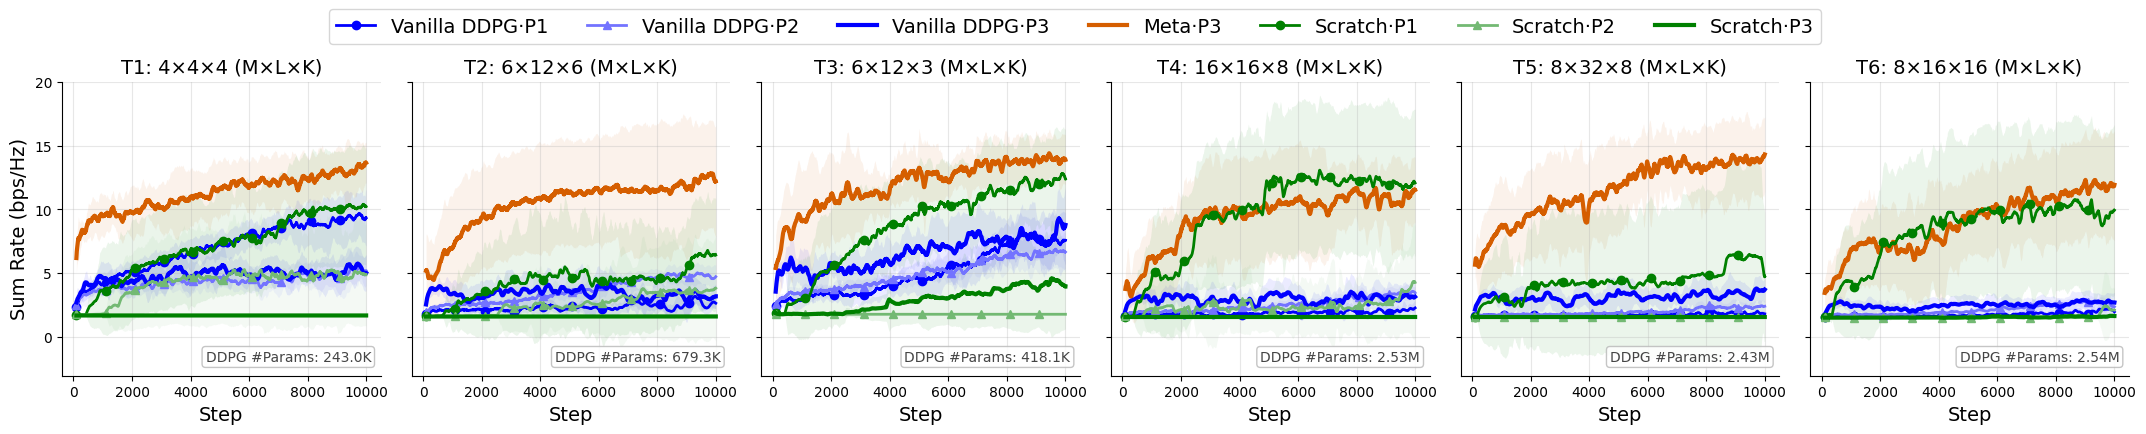

In [23]:
if not SCENE_DATA:
    print('[SKIP] No scenario data loaded; please check the diagnostic output of cell 1 first')
else:
    ordered_tids = [t for t in SCENARIOS if t in SCENE_DATA]
    n = len(ordered_tids)
    fig, axes = plt.subplots(1, n, figsize=(3.6 * n, 4.6), sharey=True)
    if n == 1:
        axes = [axes]
    for ax, tid in zip(axes, ordered_tids):
        for algo in ALGO_PARAMS:
            for p, epis in SCENE_DATA[tid].get(algo, {}).items():
                T = min(len(e) for e in epis)
                C = np.stack([curve(e[:T]) for e in epis])
                x = np.arange(C.shape[1]) + W - 1
                st = style_of(algo, p)
                ax.plot(x, C.mean(0), label=f'{ALGO_LABEL[algo]}·{p}', **st)
                ax.fill_between(x, C.mean(0) - C.std(0), C.mean(0) + C.std(0),
                                color=st['color'], alpha=0.08, lw=0)
        info = SCENARIO_INFO.get(tid, '')
        ax.set_title(f'{tid}' + (f': {info}' if info else ''), fontsize=14)
        ax.set_xlabel('Step', fontsize=14)
        ax.grid(alpha=0.3)
        ax.tick_params(direction='out')                 # ticks point outward
        ax.spines['top'].set_visible(False)             # hide top/right spines
        ax.spines['right'].set_visible(False)
        annotate_params(ax, tid)                        # annotate the DDPG parameter count in the bottom-right corner
    axes[0].set_ylabel('Sum Rate (bps/Hz)', fontsize=14)
    # fig.suptitle(f'Comparison of training curves for each simulation scenario ({W}-step moving average, mean +/- 1 std, 10 episodes)', y=0.985)
    ordered_legend(fig, axes)
    plt.tight_layout(rect=[0, 0, 1, 0.86])
    plt.show()


## Data Statistics (refer to Table I in the paper)

For each scenario T1-T6 and each **algorithm x parameter set** (not selecting the best; list all), compute over the 10 episodes:

- **First-100-step mean** (zero-shot)
- **Last-100-step mean** (final, after $10^4$ steps of adaptation)
- **Overall peak**
- Mean +/- sample standard deviation across episodes (std, ddof=1)

Missing configurations (no valid data produced) are skipped automatically.

In [15]:
import pandas as pd

# ===== Statistics convention =====
FIRST_N = 100   # first 100 steps -> zero-shot
LAST_N = 100    # last 100 steps -> final
DDOF = 1        # sample standard deviation across episodes (unbiased ddof=1); change to 0 for the population convention

# Hyper-parameter metadata for each parameter set (consistent with P1/P2/P3 in the paper Setup)
HYPER = {
    'P1': dict(lr=1e-3, tau=1e-3, noise=0.1),
    'P2': dict(lr=5e-4, tau=5e-3, noise=0.1),
    'P3': dict(lr=5e-4, tau=5e-3, noise=0.0),
}

rows = []
for tid in SCENARIOS:
    if tid not in SCENE_DATA:
        continue
    M, L, K = SCENARIO_CONFIG[tid]
    for algo in ALGO_PARAMS:
        for p in ALGO_PARAMS[algo]:
            epis = SCENE_DATA[tid].get(algo, {}).get(p)
            if not epis:
                continue
            first = np.array([np.asarray(e)[:FIRST_N].mean() for e in epis])
            last = np.array([np.asarray(e)[-LAST_N:].mean() for e in epis])
            peak = np.array([np.asarray(e).max() for e in epis])
            hy = HYPER[p]
            rows.append({
                'Test task': tid,
                'Method': ALGO_LABEL[algo],
                'Parameter set': p,
                'hidden_layer': 256 if algo == 'DDPG' else 'fixed',
                'M': M, 'L': L, 'K': K,
                'First-100 mean': round(first.mean(), 2),
                'Last-100 mean': round(last.mean(), 2),
                'Overall peak': round(peak.mean(), 2),
                'First-100 mean +/- std': f'{first.mean():.2f}±{first.std(ddof=DDOF):.2f}',
                'Last-100 mean +/- std': f'{last.mean():.2f}±{last.std(ddof=DDOF):.2f}',
                'lr': hy['lr'], 'tau': hy['tau'],
                'exploration_noise': hy['noise'],
            })

stats_df = pd.DataFrame(rows)
pd.set_option('display.unicode.east_asian_width', True)
pd.set_option('display.width', 300)
pd.set_option('display.max_columns', None)
print(f'{len(stats_df)} valid configurations in total (10 episodes per configuration)')
display(stats_df)

# To export a CSV (in the same directory as the notebook, convenient for copying into the paper), uncomment the next line:
# stats_df.to_csv('table1_stats.csv', index=False, encoding='utf-8-sig')

42 valid configurations in total (10 episodes per configuration)


,Test task,Method,Parameter set,hidden_layer,M,L,K,First-100 mean,Last-100 mean,Overall peak,First-100 mean +/- std,Last-100 mean +/- std,lr,tau,exploration_noise
0,T1,DDPG,P1,256,4,4,4,2.35,9.34,14.51,2.35±0.37,9.34±2.31,0.0010,0.001,0.1
1,T1,DDPG,P2,256,4,4,4,2.46,5.20,9.62,2.46±0.37,5.20±1.28,0.0005,0.005,0.1
2,T1,DDPG,P3,256,4,4,4,2.69,5.01,9.16,2.69±0.89,5.01±1.50,0.0005,0.005,0.0
3,T1,Meta,P3,fixed,4,4,4,6.18,13.67,17.47,6.18±1.25,13.67±1.74,0.0005,0.005,0.0
4,T1,Scratch,P1,fixed,4,4,4,1.73,10.23,13.23,1.73±0.04,10.23±4.86,0.0010,0.001,0.1
5,T1,Scratch,P2,fixed,4,4,4,1.76,4.87,9.00,1.76±0.05,4.87±4.24,0.0005,0.005,0.1
6,T1,Scratch,P3,fixed,4,4,4,1.66,1.66,1.67,1.66±0.00,1.66±0.00,0.0005,0.005,0.0
7,T2,DDPG,P1,256,6,12,6,1.81,2.62,5.83,1.81±0.13,2.62±0.45,0.0010,0.001,0.1
8,T2,DDPG,P2,256,6,12,6,1.90,4.71,7.26,1.90±0.24,4.71±1.01,0.0005,0.005,0.1
9,T2,DDPG,P3,256,6,12,6,2.53,3.17,6.31,2.53±0.60,3.17±0.99,0.0005,0.005,0.0
